# Anomaly detection in IoT network traffic: v2

**Short version.** v1 of this project (a course assignment) caught 16 of 21,222 malicious connections. This notebook explains
why, redoes the work on the right kind of data, and measures it honestly: every detector is scored on a capture it never saw.
The unsupervised detector then finds every malicious connection in all four held-out captures at a 5% false-alarm budget.

The v1 notebook is [`ML_unsupervised_learning.ipynb`](ML_unsupervised_learning.ipynb) (tag `v1-coursework`).
Everything here is regenerated by running this notebook; the numbers match `v2/results.json`.

In [1]:
import sys, json
sys.path.insert(0, ".")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import anomaly_features as af
import anomaly_experiment as ex

frames, feats = ex.load_all()
print({c: len(f) for c, f in frames.items()}, "connections per capture")

{'20': 3209, '21': 3286, '42': 4426, '44': 237, '34': 23145, '8': 10403} connections per capture


## 1. Why v1 failed

An anomaly detector assumes bad behaviour is **rare**. v1 used capture 34 and told Isolation Forest that 1% of the traffic is
anomalous (`contamination=0.01`). Look at what the capture actually contains:

In [2]:
share = pd.DataFrame({c: {"connections": len(f), "malicious": int(f["malicious"].sum()),
                          "% malicious": round(100 * f["malicious"].mean(), 1)} for c, f in frames.items()}).T
share[["connections", "malicious"]] = share[["connections", "malicious"]].astype(int)
share.index = [f"capture {c}" + ("  <- v1 used this one" if c == "34" else "") for c in share.index]
share.sort_values("% malicious")

,connections,malicious,% malicious
capture 42,4426,6,0.1
capture 21,3286,14,0.4
capture 20,3209,16,0.5
capture 44,237,26,11.0
capture 8,10403,8222,79.0
capture 34 <- v1 used this one,23145,21222,91.7


Capture 34 is **92% malicious**. "Flag the rarest 1%" selects the wrong rows by construction, no matter how good the features
are. Running v1's method with the v2 features on that capture confirms it:

In [3]:
v1 = ex.v1_setting(frames, feats)
print(f"flagged {v1['flagged']} connections; {v1['malicious_caught']} of {v1['malicious']:,} malicious ones among them "
      f"({v1['malicious_caught'] / v1['malicious']:.1%} recall)")

flagged 232 connections; 120 of 21,222 malicious ones among them (0.6% recall)


The dataset has captures that *are* the textbook case: thousands of ordinary connections with a handful of malicious ones
(captures 20, 21, 42, 44 above). v2 uses those.

## 2. Features

One row per connection. The features leave out three things on purpose:

- **the labels** (obviously);
- **IP addresses**: an address identifies a device, and across captures it identifies the scenario, so a model could "detect" the
  capture instead of the behaviour;
- **the timestamp**.

What is left: sizes and packet counts (log-scaled, with a missing-value flag), the protocol, the connection state, the kind of
destination port, how long the connection history string is, and one feature that looks only at the **past**: how many
connections the same source opened in the last 10 seconds (scans and beacons show up as bursts).

In [4]:
X = feats["20"]
print(X.shape[1], "features, identical for every capture")
X.describe().T[["mean", "max"]].round(2).head(12)

37 features, identical for every capture


,mean,max
log_duration,0.18,10.70
missing_duration,0.28,1.00
log_orig_bytes,2.87,9.87
missing_orig_bytes,0.28,1.00
log_resp_bytes,2.62,9.87
missing_resp_bytes,0.28,1.00
log_orig_pkts,0.74,9.09
missing_orig_pkts,0.00,0.00
log_orig_ip_bytes,4.41,12.83
missing_orig_ip_bytes,0.00,0.00


## 3. How to score it honestly

Two choices make the difference between a flattering number and a true one.

**Hold out a whole capture.** Each of the four mostly-benign captures is left out in turn. The detectors are fitted on the
*other* captures and scored on the one they have never seen. (v1 fitted and scored on the same rows.)

**Use metrics that fit rare events.** With 0.5% malicious, accuracy is meaningless: answering "benign" every time scores 99.5%.
Instead:

- **average precision**: how high the malicious connections rank in the detector's list (random guessing scores the share of
  malicious connections, shown as a red line later);
- **recall at a fixed false-alarm rate**: of the malicious connections, how many are caught if we only tolerate false alarms on
  1% (or 5%) of the benign ones. This is what an analyst reading alerts actually experiences.

In [5]:
# A tiny worked example of recall at a false-alarm budget
y = np.array([0] * 98 + [1, 1])
score = np.concatenate([np.linspace(0, 0.5, 98), [0.9, 0.3]])
for fpr in (0.01, 0.5):
    print(f"false-alarm budget {fpr:.0%}: recall = {af.recall_at_fpr(y, score, fpr):.2f}")

false-alarm budget 1%: recall = 0.50
false-alarm budget 50%: recall = 1.00


## 4. One capture by hand: capture 42

Capture 42 has 4,426 connections and **6 malicious** ones. Fit an Isolation Forest on the other three mostly-benign captures
(no labels), then score capture 42.

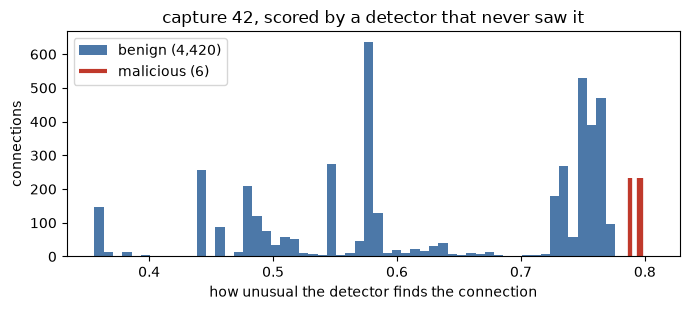

recall at 1% false alarms: 1.00


In [6]:
from sklearn.ensemble import IsolationForest
train = pd.concat([feats[c].sample(min(20000, len(feats[c])), random_state=0) for c in ["20", "21", "44"]])
iso = IsolationForest(n_estimators=300, random_state=0).fit(train)
y42 = frames["42"]["malicious"].to_numpy()
s42 = -iso.score_samples(feats["42"])                      # higher = more unusual

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(s42[y42 == 0], bins=60, color="#4c78a8", label=f"benign ({(y42 == 0).sum():,})")
ax.vlines(s42[y42 == 1], 0, ax.get_ylim()[1] * 0.35, colors="#c0392b", lw=3, label=f"malicious ({y42.sum()})")
ax.set_xlabel("how unusual the detector finds the connection"); ax.set_ylabel("connections")
ax.legend(); ax.set_title("capture 42, scored by a detector that never saw it"); plt.tight_layout(); plt.show()
print(f"recall at 1% false alarms: {af.recall_at_fpr(y42, s42, 0.01):.2f}")

The six malicious connections score higher than every benign one: they sit just past the most unusual ordinary traffic. The
margin is thin (most benign connections cluster below), which is why the next section uses a budget of false alarms rather than a
single cut-off. The detector never learned what "malicious" means; it learned what ordinary traffic looks like, and these
connections are not ordinary.

## 5. The full experiment

Every mostly-benign capture held out in turn, three methods:

- **Isolation Forest** and **Local Outlier Factor**: unsupervised, fitted on the other captures without labels.
- **Supervised baseline**: a gradient-boosted classifier that *does* use labels, trained on the other captures plus the
  mostly-malicious captures 34 and 8. It shows what labels buy.

In [7]:
out, scores = ex.run_experiment(frames, feats, keep_scores=True)
res, order = out["held_out_captures"], ex.BENIGN_DOMINATED
names = {"isolation_forest": "Isolation Forest", "local_outlier_factor": "Local Outlier Factor", "supervised_baseline": "Supervised baseline"}
rows = []
for h in order:
    for m in ex.METHODS:
        rows.append({"capture": f"{h} ({res[h]['malicious']} of {res[h]['connections']:,})", "method": names[m],
                     "average precision": round(res[h][m]["average_precision"], 2),
                     "recall @1% false alarms": round(res[h][m]["recall_at_1pct_fpr"], 2),
                     "recall @5% false alarms": round(res[h][m]["recall_at_5pct_fpr"], 2)})
pd.DataFrame(rows).set_index(["capture", "method"])

average precision  \
capture          method                                    
20 (16 of 3,209) Isolation Forest                   0.29   
                 Local Outlier Factor               0.10   
                 Supervised baseline                0.84   
21 (14 of 3,286) Isolation Forest                   0.34   
                 Local Outlier Factor               0.03   
                 Supervised baseline                0.94   
42 (6 of 4,426)  Isolation Forest                   0.59   
                 Local Outlier Factor               0.00   
                 Supervised baseline                0.00   
44 (26 of 237)   Isolation Forest                   0.94   
                 Local Outlier Factor               0.96   
                 Supervised baseline                0.92   

                                       recall @1% false alarms  \
capture          method                                          
20 (16 of 3,209) Isolation Forest                         0.19   
                 Local Outlier Factor                     0.06   
                 Supervised baseline                      0.94   
21 (14 of 3,286) Isolation Forest                         0.21   
                 Local Outlier Factor                     0.21   
                 Supervised baseline                      1.00   
42 (6 of 4,426)  Isolation Forest                         1.00   
                 Local Outlier Factor                     0.00   
                 Supervised baseline                      0.00   
44 (26 of 237)   Isolation Forest                         1.00   
                 Local Outlier Factor                     0.96   
                 Supervised baseline                      0.58   

                                       recall @5% false alarms  
capture          method                                         
20 (16 of 3,209) Isolation Forest                         1.00  
                 Local Outlier Factor                     0.38  
                 Supervised baseline                      0.94  
21 (14 of 3,286) Isolation Forest                         1.00  
                 Local Outlier Factor                     0.21  
                 Supervised baseline                      1.00  
42 (6 of 4,426)  Isolation Forest                         1.00  
                 Local Outlier Factor                     0.00  
                 Supervised baseline                      0.00  
44 (26 of 237)   Isolation Forest                         1.00  
                 Local Outlier Factor                     1.00  
                 Supervised baseline                      1.00

In [8]:
mean = pd.DataFrame(out["mean_over_captures"]).T.rename(index=names).round(2)
mean.loc["Random guessing"] = [round(out["mean_prevalence"], 2), 0.01, 0.05]
mean

,average_precision,recall_at_1pct_fpr,recall_at_5pct_fpr
Isolation Forest,0.54,0.60,1.00
Local Outlier Factor,0.27,0.31,0.40
Supervised baseline,0.68,0.63,0.73
Random guessing,0.03,0.01,0.05


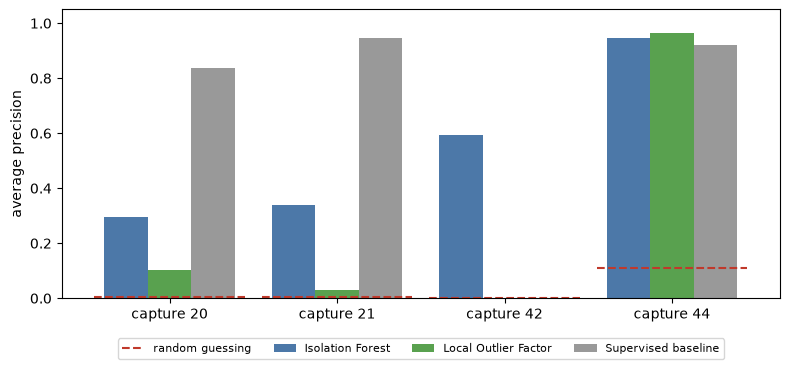

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8)); w = 0.26; x = np.arange(len(order))
for i, m in enumerate(ex.METHODS):
    ax.bar(x + (i - 1) * w, [res[h][m]["average_precision"] for h in order], w, label=names[m], color=["#4c78a8", "#59a14f", "#999"][i])
for j, h in enumerate(order):
    ax.hlines(res[h]["prevalence"], j - 0.45, j + 0.45, colors="#c0392b", linestyles="--", label="random guessing" if j == 0 else None)
ax.set_xticks(x); ax.set_xticklabels([f"capture {h}" for h in order]); ax.set_ylabel("average precision"); ax.set_ylim(0, 1.05)
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12)); plt.tight_layout(); plt.show()

## 6. What the results say

**Unsupervised detection works here.** Isolation Forest, with no labels, ranks the malicious connections far above chance on
captures it has never seen, and at a 5% false-alarm budget it catches **every** malicious connection in all four.

**Labels help only for attacks the model has seen.** Compare the supervised baseline on captures 20 and 21 (Torii command-and-control,
which the other capture taught it) with capture 42 (file download, which nothing taught it):

In [10]:
for h in order:
    r = res[h]
    print(f"capture {h}: attacks {r['attack_types']}\n"
          f"   recall @1% false alarms: isolation forest {r['isolation_forest']['recall_at_1pct_fpr']:.2f}, "
          f"supervised {r['supervised_baseline']['recall_at_1pct_fpr']:.2f}")

capture 20: attacks {'Torii': 16}
   recall @1% false alarms: isolation forest 0.19, supervised 0.94
capture 21: attacks {'Torii': 14}
   recall @1% false alarms: isolation forest 0.21, supervised 1.00
capture 42: attacks {'': 3, 'FileDownload': 3}
   recall @1% false alarms: isolation forest 1.00, supervised 0.00
capture 44: attacks {'': 15, 'FileDownload': 11}
   recall @1% false alarms: isolation forest 1.00, supervised 0.58


The supervised model is excellent on Torii (0.94 and 1.00), catches **nothing** on capture 42's file-download attack and about
half on capture 44's; the unsupervised detector is the reverse (weak on Torii, perfect on both file-download captures). A supervised classifier can only recognise what it was shown; an anomaly detector can flag the unfamiliar.
A practical system would use both.

**Local Outlier Factor is clearly worse** on these features.

## 7. Limits

- The malicious counts are tiny (6 to 26 per capture), so every number is a wide estimate. Differences between methods on a single
  capture are not conclusive.
- Four captures from one dataset: nothing here says how it would do on a real network.
- Training samples are capped at 20,000 rows per capture.
- v1 asked an "unsupervised" question of a labelled, mostly-malicious capture; the lesson carries over: **check that the data
  fits the method before tuning the method.**

## 8. Reproduce

```bash
scripts/fetch-data.sh
.venv/bin/python v2/run.py                      # results.json and the figure
.venv/bin/python v2/build_notebook.py           # this notebook, executed
```

In [11]:
# consistency check: the notebook and v2/run.py agree
saved = json.load(open("v2/results.json"))
assert saved["mean_over_captures"] == out["mean_over_captures"], "notebook and v2/results.json disagree"
print("matches v2/results.json")

matches v2/results.json
